[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_3_Analisis_Exploratorio.ipynb)

# Fase 3. Análisis exploratorio de datos

En esta fase describo el conjunto de entrenamiento. Para que el EDA siga siendo fácil de leer, me centro en cinco propiedades fisicoquímicas: peso molecular, LogP, donantes, aceptores y TPSA. No son los únicos descriptores disponibles: calculé el catálogo numérico de RDKit completo y lo usaré para seleccionar predictores en los modelos. Mantengo el conjunto de prueba reservado para evaluarlos.

## 3.1. Lectura de los datos

Leo los CSV preparados en la fase anterior desde la carpeta pública del proyecto. Así puedo ejecutar este notebook sin subir archivos manualmente.

In [1]:
%pip -q install rdkit


In [2]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
dilist['nombre_normalizado'] = dilist['CompoundName'].astype('string').str.strip().str.casefold()  # Quito espacios laterales para evitar falsos no encontrados.
estructuras['nombre_normalizado'] = estructuras['CompoundName'].astype('string').str.strip().str.casefold()  # Creo la misma clave normalizada en el mapa.
datos = dilist.merge(estructuras.drop(columns='CompoundName'), on='nombre_normalizado', how='left')  # Uno por nombre normalizado sin perder la etiqueta original.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

He cargado los datos del repositorio: /content/datos_dili
Descriptores numéricos disponibles: 218


## 3.2. Resumen univariado

Para cada descriptor calculo media, mediana, moda, desviación estándar, mínimo, máximo y cuartiles. También cuento las etiquetas DILI en valores absolutos y relativos.

In [3]:
# Selecciono cinco propiedades fisicoquímicas fáciles de interpretar.
variables = ['MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA']  # Escojo las variables de Lipinski y TPSA.
variables = [variable for variable in variables if variable in train_df.columns]  # Confirmo que estén en el conjunto.

# Calculo las medidas de resumen univariado con entrenamiento.
resumen = train_df[variables].describe().T  # Obtengo media, desviación, mínimo, cuartiles y máximo.
resumen['mediana'] = train_df[variables].median()  # Añado la mediana.
resumen['moda'] = train_df[variables].mode().iloc[0]  # Añado la moda más frecuente.
display(resumen.round(2))  # Muestro el resumen redondeado.
print('Lectura de las medidas:')  # Inicio el comentario de los resultados calculados.
for variable in variables:  # Recorro las propiedades estudiadas.
    print(f"{variable}: mediana {resumen.loc[variable, 'mediana']:.2f}; la mitad central está entre {resumen.loc[variable, '25%']:.2f} y {resumen.loc[variable, '75%']:.2f}.")  # Interpreto centro y dispersión observados.

# Cuento las clases DILI en frecuencia absoluta y relativa.
frecuencias = train_df['DILI'].value_counts().sort_index().to_frame('frecuencia')  # Cuento registros por clase.
frecuencias['porcentaje'] = (100 * frecuencias['frecuencia'] / len(train_df)).round(1)  # Calculo porcentajes.
frecuencias.index = frecuencias.index.map({0: 'DILI negativa', 1: 'DILI positiva'})  # Pongo nombres legibles.
display(frecuencias)  # Muestro la distribución de clases.
print(f"En train, {frecuencias.loc['DILI positiva', 'porcentaje']:.1f}% tiene etiqueta positiva y {frecuencias.loc['DILI negativa', 'porcentaje']:.1f}% negativa.")  # Comento el balance observado.


,count,mean,std,min,25%,50%,75%,max,mediana,moda
MolWt,945.0,418.54,449.44,46.07,260.31,334.40,430.54,7053.95,334.40,287.36
MolLogP,945.0,1.74,3.91,-49.12,0.67,2.37,3.70,9.25,2.37,-3.59
NumHDonors,945.0,2.91,6.76,0.00,1.00,2.00,3.00,100.00,2.00,1.00
NumHAcceptors,945.0,5.81,7.07,0.00,3.00,4.00,6.00,99.00,4.00,2.00
TPSA,945.0,112.31,194.37,0.00,46.25,74.97,115.06,2912.95,74.97,37.30


Lectura de las medidas:
MolWt: mediana 334.40; la mitad central está entre 260.31 y 430.54.
MolLogP: mediana 2.37; la mitad central está entre 0.67 y 3.70.
NumHDonors: mediana 2.00; la mitad central está entre 1.00 y 3.00.
NumHAcceptors: mediana 4.00; la mitad central está entre 3.00 y 6.00.
TPSA: mediana 74.97; la mitad central está entre 46.25 y 115.06.


,frecuencia,porcentaje
DILI,,
DILI negativa,361,38.2
DILI positiva,584,61.8


En train, 61.8% tiene etiqueta positiva y 38.2% negativa.


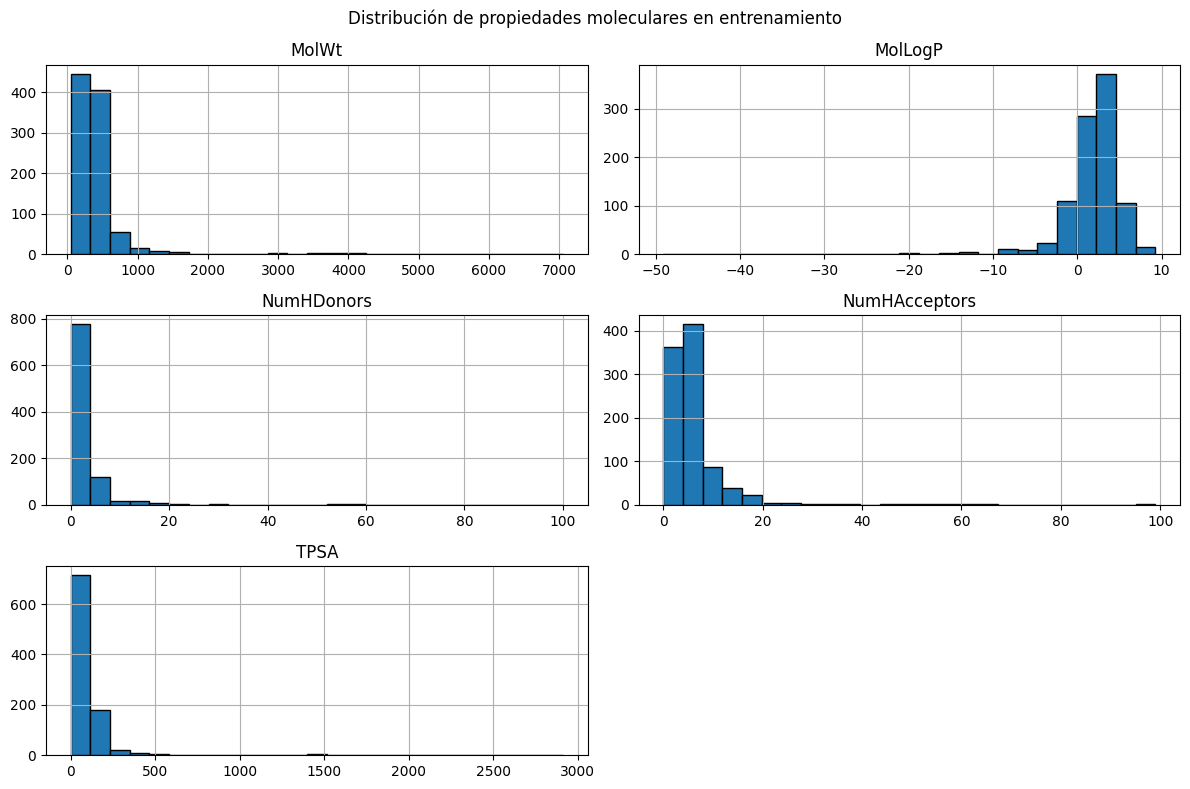

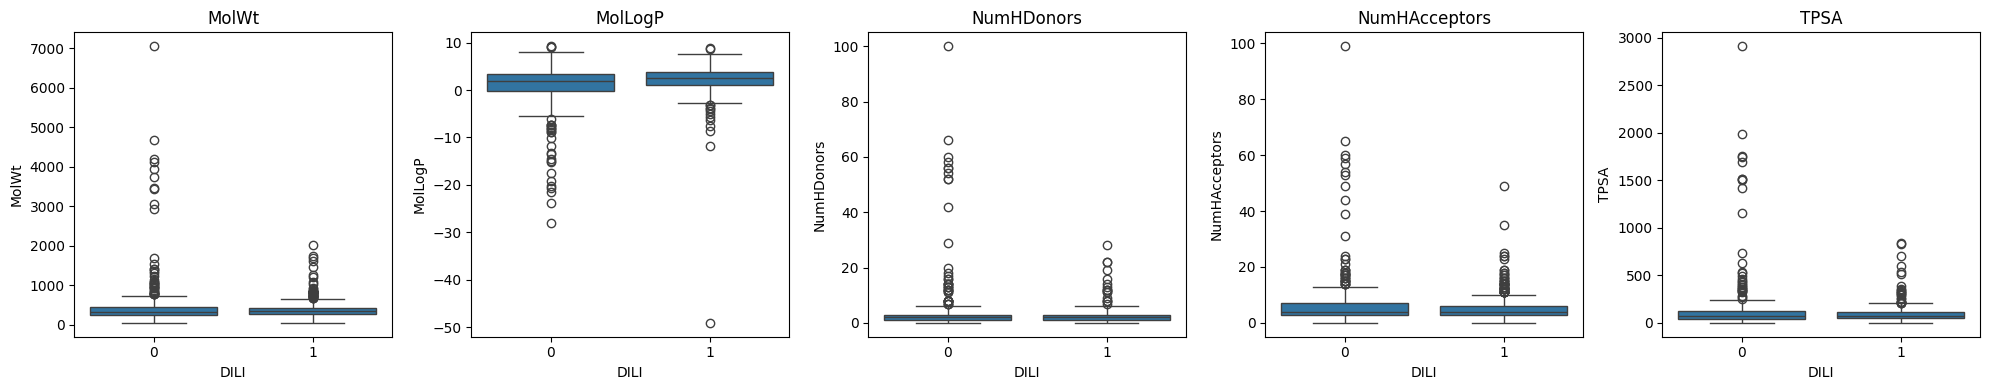

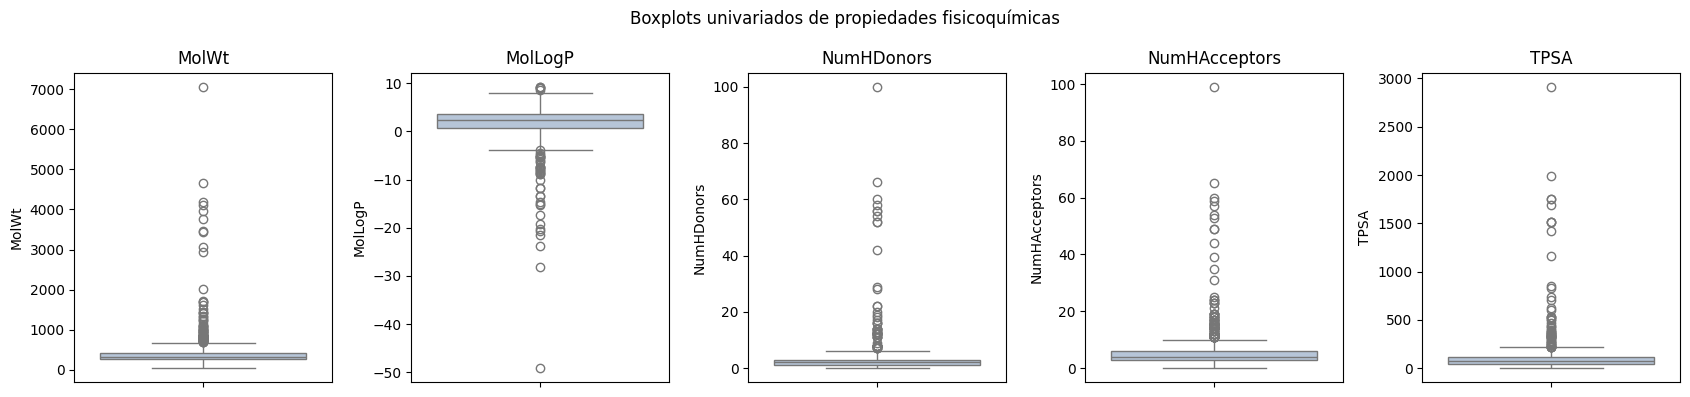

Los puntos fuera de los bigotes son observaciones que el criterio 1,5 × RIC marca para el análisis de extremos.
MolWt: mediana DILI negativa = 332.46; positiva = 334.79.
MolLogP: mediana DILI negativa = 1.89; positiva = 2.64.
NumHDonors: mediana DILI negativa = 2.00; positiva = 2.00.
NumHAcceptors: mediana DILI negativa = 4.00; positiva = 4.00.
TPSA: mediana DILI negativa = 74.60; positiva = 75.27.


In [4]:
# Importo herramientas para dibujar histogramas y diagramas de caja.
import matplotlib.pyplot as plt  # Creo gráficos.
import seaborn as sns  # Dibujo comparaciones por clase.

# Represento la forma de las distribuciones de cada descriptor.
train_df[variables].hist(figsize=(12, 8), bins=25, edgecolor='black')  # Dibujo un histograma por variable.
plt.suptitle('Distribución de propiedades moleculares en entrenamiento')  # Titulo la figura.
plt.tight_layout()  # Ajusto los espacios entre gráficos.
plt.show()  # Muestro los histogramas.

# Comparo cada propiedad entre las dos clases de DILI.
fig, axes = plt.subplots(1, len(variables), figsize=(4 * len(variables), 4))  # Creo un panel de diagramas.
for ax, variable in zip(axes, variables):  # Recorro cada descriptor y su eje.
    sns.boxplot(data=train_df, x='DILI', y=variable, ax=ax)  # Dibujo cajas por clase.
    ax.set_title(variable)  # Pongo el nombre del descriptor.
plt.tight_layout()  # Acomodo los títulos.
plt.show()  # Muestro las comparaciones.

# Represento boxplots univariados para ver medianas, dispersión y extremos.
fig, axes = plt.subplots(1, len(variables), figsize=(3.4 * len(variables), 4))  # Creo un panel por propiedad.
for ax, variable in zip(axes, variables):  # Recorro los descriptores seleccionados.
    sns.boxplot(y=train_df[variable], ax=ax, color='lightsteelblue', showfliers=True)  # Dibujo caja y observaciones extremas.
    ax.set_title(variable)  # Identifico la propiedad representada.
    ax.set_xlabel('')  # Quito una etiqueta que no aporta información.
plt.suptitle('Boxplots univariados de propiedades fisicoquímicas')  # Titulo la figura.
plt.tight_layout()  # Ajusto el espacio entre paneles.
plt.show()  # Muestro los boxplots individuales.
print('Los puntos fuera de los bigotes son observaciones que el criterio 1,5 × RIC marca para el análisis de extremos.')  # Explico el boxplot.
for variable in variables:  # Comparo las medianas que aparecen en los boxplots por clase.
    medianas_clase = train_df.groupby('DILI')[variable].median()  # Calculo una mediana para cada etiqueta.
    print(f"{variable}: mediana DILI negativa = {medianas_clase.get(0, np.nan):.2f}; positiva = {medianas_clase.get(1, np.nan):.2f}.")  # Comento la diferencia observada.



## 3.3. Calidad de los datos y valores atípicos

Reviso nulos, duplicados y posibles valores atípicos. Uso el criterio de 1,5 veces el rango intercuartílico (RIC) en MolWt, MolLogP, donantes, aceptores y TPSA. Calculo los límites con train y retiro de train y test cualquier compuesto que quede fuera en al menos una propiedad. Antes del filtro, muestro algunas estructuras para revisar qué tipo de compuestos identifica.

In [5]:
# Calculo los valores ausentes y los duplicados antes de filtrar.
calidad = pd.DataFrame({'nulos': datos_limpios.isna().sum(), 'porcentaje_nulos': (100 * datos_limpios.isna().mean()).round(1)})  # Resumo valores ausentes.
display(calidad.sort_values('porcentaje_nulos', ascending=False).head(12))  # Muestro primero las columnas con más nulos.
print('Nombres sin estructura inequívoca:', datos['InChIKey'].isna().sum())  # Informo cobertura de estructuras.
print('Nombres repetidos en DILIst:', dilist['CompoundName'].duplicated().sum())  # Cuento nombres repetidos.
print('InChIKey repetidas en train:', train_df['InChIKey'].duplicated().sum())  # Compruebo duplicados químicos.
print('Filas con etiquetas contradictorias:', len(datos_conflicto))  # Muestro posibles conflictos.

# Calculo límites de 1,5 × RIC solo con train.
q1 = train_df[variables].quantile(0.25)  # Calculo el primer cuartil.
q3 = train_df[variables].quantile(0.75)  # Calculo el tercer cuartil.
ric = q3 - q1  # Calculo el rango intercuartílico.
lim_inf = q1 - 1.5 * ric  # Defino límites inferiores.
lim_sup = q3 + 1.5 * ric  # Defino límites superiores.
fuera_train = train_df[variables].lt(lim_inf) | train_df[variables].gt(lim_sup)  # Marco extremos por variable en train.
fuera_test = test_df[variables].lt(lim_inf) | test_df[variables].gt(lim_sup)  # Aplico a test los mismos límites.
tabla_outliers = pd.DataFrame({'límite inferior': lim_inf, 'límite superior': lim_sup, 'train': fuera_train.sum(), 'test': fuera_test.sum()})  # Organizo umbrales y recuentos.
tabla_outliers['train (%)'] = (100 * tabla_outliers['train'] / len(train_df)).round(1)  # Calculo porcentaje en train.
tabla_outliers['test (%)'] = (100 * tabla_outliers['test'] / len(test_df)).round(1)  # Calculo porcentaje en test.
display(tabla_outliers.round(2))  # Muestro los resultados.
mask_outlier_train = fuera_train.any(axis=1)  # Marco compuestos fuera de rango en al menos una propiedad.
mask_outlier_test = fuera_test.any(axis=1)  # Aplico la misma regla a test.
print(f"Train: retiro {mask_outlier_train.sum()} de {len(train_df)} compuestos ({100 * mask_outlier_train.mean():.1f}%).")  # Cuantifico la retirada.
print(f"Test: retiro {mask_outlier_test.sum()} de {len(test_df)} compuestos ({100 * mask_outlier_test.mean():.1f}%).")  # Cuantifico la retirada.
print('Calculo los límites solo con train y los aplico sin recalcularlos a test.')  # Explico el control de las particiones.


,nulos,porcentaje_nulos
Routes_of_Administration,251,21.2
BCUT2D_MWLOW,31,2.6
BCUT2D_MWHI,31,2.6
BCUT2D_LOGPLOW,31,2.6
BCUT2D_CHGHI,31,2.6
BCUT2D_CHGLO,31,2.6
BCUT2D_LOGPHI,31,2.6
BCUT2D_MRLOW,31,2.6
BCUT2D_MRHI,31,2.6
MinPartialCharge,3,0.3


Nombres sin estructura inequívoca: 93
Nombres repetidos en DILIst: 0
InChIKey repetidas en train: 0
Filas con etiquetas contradictorias: 0


,límite inferior,límite superior,train,test,train (%),test (%)
MolWt,4.97,685.88,75,18,7.9,7.6
MolLogP,-3.87,8.25,42,10,4.4,4.2
NumHDonors,-2.00,6.00,56,13,5.9,5.5
NumHAcceptors,-1.50,10.50,98,20,10.4,8.4
TPSA,-56.96,218.28,56,15,5.9,6.3


Train: retiro 121 de 945 compuestos (12.8%).
Test: retiro 31 de 237 compuestos (13.1%).
Calculo los límites solo con train y los aplico sin recalcularlos a test.


### Lectura de calidad y extremos

Las ausencias se concentran en Routes_of_Administration (251 de 1.182; 21,2 %) y en ocho descriptores BCUT2D (31 registros por columna; 2,6 %); cuatro descriptores de carga parcial tienen tres ausencias cada uno (0,3 %). No hay InChIKey duplicadas en train ni etiquetas contradictorias. Los límites del filtro son MolWt 4,97–685,88; MolLogP −3,87–8,25; donantes −2–6; aceptores −1,5–10,5; y TPSA −56,96–218,28. Marco una fila si rebasa al menos uno de ellos. A continuación muestro tres estructuras marcadas para comprobar que parte de los extremos son compuestos reales y reconocibles.


,CompoundName,DILI,MolWt,MolLogP,NumHDonors,NumHAcceptors,TPSA,criterio
219,montelukast,1,586.20,8.95,2.0,4.0,70.42,MolLogP
403,atazanavir,1,704.87,4.21,5.0,9.0,171.22,MolWt
758,fondaparinux sodium,1,1728.09,-49.12,9.0,49.0,833.78,"MolWt, MolLogP, NumHDonors, NumHAcceptors, TPSA"


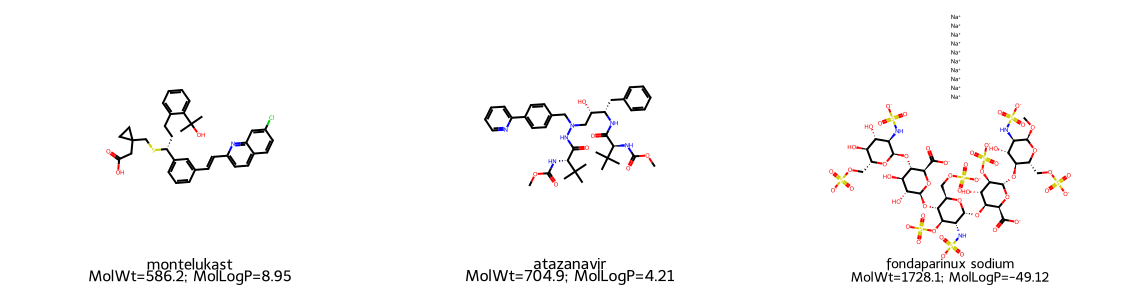

La figura permite revisar visualmente los compuestos que excluiré de los análisis posteriores.


In [6]:
# Selecciono tres compuestos de train marcados por el filtro.
compuestos_atipicos = train_df.loc[mask_outlier_train].copy()  # Reúno las filas que se retirarán.
nombres_ejemplo = ['atazanavir', 'montelukast', 'fondaparinux sodium']  # Elijo perfiles moleculares distintos.
ejemplos_atipicos = compuestos_atipicos[compuestos_atipicos['CompoundName'].str.casefold().isin(nombres_ejemplo)].copy()  # Localizo los ejemplos.
ejemplos_atipicos['criterio'] = ejemplos_atipicos.apply(lambda fila: ', '.join([v for v in variables if fuera_train.loc[fila.name, v]]), axis=1)  # Indico qué propiedad excede el límite.
columnas_ejemplo = ['CompoundName', 'DILI', 'MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA', 'criterio']  # Selecciono los datos a mostrar.
display(ejemplos_atipicos[columnas_ejemplo].round(2))  # Muestro sus valores.

# Dibujo las estructuras junto al nombre, peso molecular y MolLogP.
from rdkit import Chem  # Leo moléculas desde SMILES.
from rdkit.Chem import Draw  # Dibujo las estructuras químicas.
moleculas = []  # Guardo estructuras válidas.
leyendas = []  # Guardo las etiquetas de cada dibujo.
for _, fila in ejemplos_atipicos.iterrows():  # Recorro los compuestos escogidos.
    mol = Chem.MolFromSmiles(fila['SMILES'])  # Construyo una molécula desde SMILES.
    if mol is not None:  # Compruebo que RDKit la reconoce.
        moleculas.append(mol)  # Añado la estructura.
        leyendas.append(f"{fila['CompoundName']}\nMolWt={fila['MolWt']:.1f}; MolLogP={fila['MolLogP']:.2f}")  # Identifico el dibujo.
if moleculas:  # Compruebo que haya estructuras válidas.
    display(Draw.MolsToGridImage(moleculas, molsPerRow=3, subImgSize=(380, 300), legends=leyendas))  # Muestro las tres juntas.
print('La figura permite revisar visualmente los compuestos que excluiré de los análisis posteriores.')  # Interpreto los ejemplos.


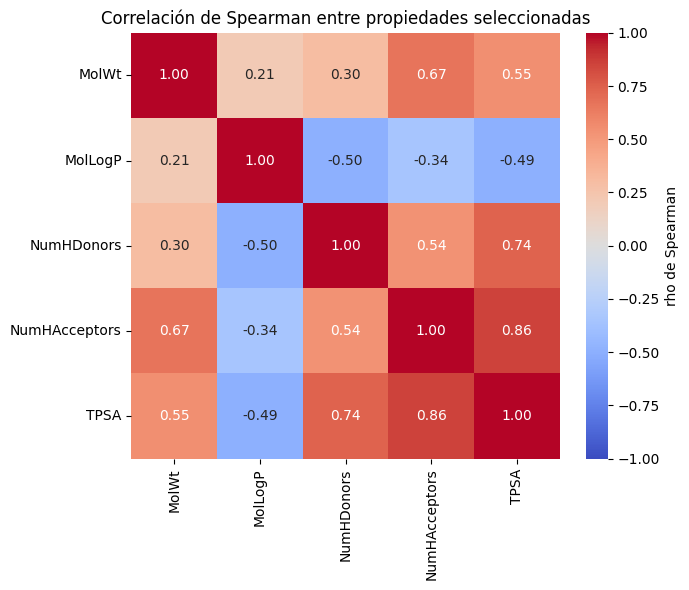

,descriptor,Spearman con DILI,n observaciones
0,FractionCSP3,-0.211135,945
1,BCUT2D_LOGPLOW,0.175377,920
2,fr_Al_OH,-0.170373,945
3,SMR_VSA6,-0.168753,945
4,SlogP_VSA2,-0.167636,945
5,fr_Ndealkylation1,-0.165648,945
6,MolLogP,0.163616,945
7,BCUT2D_MRHI,0.163499,920
8,fr_quatN,-0.153011,945
9,PEOE_VSA1,-0.146459,945


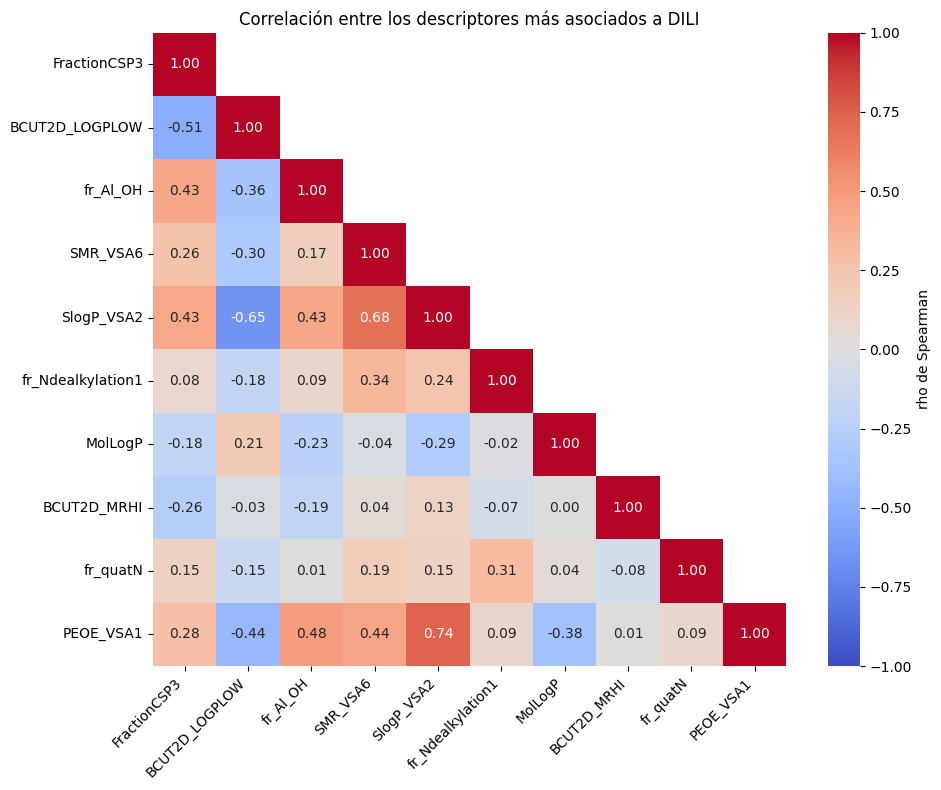

DILI,0,1,diferencia positiva-negativa
MolWt,332.46,334.79,2.33
MolLogP,1.89,2.64,0.75
TPSA,74.60,75.27,0.67
NumHDonors,2.00,2.00,0.00
NumHAcceptors,4.00,4.00,0.00


,Spearman con DILI
MolLogP,0.163616
NumHDonors,-0.068528
NumHAcceptors,-0.038106
TPSA,-0.027208
MolWt,-0.014806


Entre las cinco propiedades, MolLogP tiene la mayor asociación monotónica con DILI (rho = 0.16).
Las correlaciones describen asociaciones; no demuestran causalidad.


In [7]:
# Calculo la correlación entre las cinco propiedades fisicoquímicas del EDA.
correlaciones = train_df[variables].corr(method='spearman')  # Calculo Spearman con entrenamiento.
fig, ax = plt.subplots(figsize=(7, 6))  # Creo una figura independiente para esta matriz.
sns.heatmap(correlaciones, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, cbar_kws={'label': 'rho de Spearman'}, ax=ax)  # Represento una sola barra de color.
ax.set_title('Correlación de Spearman entre propiedades seleccionadas')  # Titulo el mapa.
plt.tight_layout()  # Ajusto la figura.
plt.show()  # Muestro la matriz.

# Reviso la asociación de los descriptores con DILI y retiro columnas con demasiados valores ausentes.
variables_amplias = [variable for variable in DESCRIPTORES if variable not in ['DILI', 'DILIST_ID'] and train_df[variable].notna().mean() >= 0.80 and train_df[variable].nunique(dropna=True) > 1]  # Filtro propiedades con suficientes observaciones.
correlacion_dili = train_df[variables_amplias + ['DILI']].corr(method='spearman', min_periods=100)['DILI'].drop('DILI').dropna()  # Calculo asociación con al menos cien pares.
top_asociaciones = correlacion_dili.abs().sort_values(ascending=False).head(15)  # Selecciono las quince asociaciones mayores.
resumen_asociaciones = pd.DataFrame({'descriptor': top_asociaciones.index, 'Spearman con DILI': correlacion_dili.loc[top_asociaciones.index].values, 'n observaciones': train_df[top_asociaciones.index].notna().sum().values})  # Añado el tamaño de cada comparación.
display(resumen_asociaciones)  # Muestro las asociaciones y sus tamaños.

# Represento la correlación entre los diez descriptores con mayor asociación a DILI.
top_diez = top_asociaciones.head(10).index.tolist()  # Selecciono diez variables para la matriz.
matriz_amplia = train_df[top_diez].corr(method='spearman', min_periods=100)  # Calculo correlaciones con al menos cien observaciones comunes.
fig, ax = plt.subplots(figsize=(10, 8))  # Creo una segunda figura independiente.
mascara = np.triu(np.ones_like(matriz_amplia, dtype=bool), k=1)  # Oculto la mitad superior repetida.
sns.heatmap(matriz_amplia, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'label': 'rho de Spearman'}, ax=ax)  # Dibujo una matriz legible con una barra.
ax.set_title('Correlación entre los descriptores más asociados a DILI')  # Titulo la segunda matriz.
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')  # Giro los nombres para que no se solapen.
plt.tight_layout()  # Ajusto etiquetas y márgenes.
plt.show()  # Muestro la matriz amplia.

# Comparo las medianas de las cinco propiedades del EDA entre las clases DILI.
medianas = train_df.groupby('DILI')[variables].median().T  # Calculo medianas por clase.
medianas['diferencia positiva-negativa'] = medianas[1] - medianas[0]  # Calculo una diferencia descriptiva.
display(medianas.sort_values('diferencia positiva-negativa', key=abs, ascending=False).round(2))  # Ordeno por diferencia absoluta.

# Calculo la asociación de las cinco propiedades seleccionadas con DILI.
relacion = train_df[variables + ['DILI']].corr(method='spearman')['DILI'].drop('DILI')  # Extraigo la correlación con la etiqueta.
display(relacion.sort_values(key=abs, ascending=False).to_frame('Spearman con DILI'))  # Muestro las asociaciones seleccionadas.
variable_mayor = relacion.abs().idxmax()  # Localizo la asociación de mayor magnitud.
print(f"Entre las cinco propiedades, {variable_mayor} tiene la mayor asociación monotónica con DILI (rho = {relacion[variable_mayor]:.2f}).")  # Comento signo y magnitud observados.
print('Las correlaciones describen asociaciones; no demuestran causalidad.')  # Aclaro su alcance.


In [8]:
# Resumo el balance de etiquetas antes del filtro.
proporciones = train_df['DILI'].value_counts(normalize=True)  # Calculo proporciones originales.
print(f"Antes del filtro, DILI positiva representa {100 * proporciones.get(1, 0):.1f}% y DILI negativa {100 * proporciones.get(0, 0):.1f}% de train.")  # Explico el balance.

# Comparo las medianas originales de MolLogP por clase.
medianas_logp = train_df.groupby('DILI')['MolLogP'].median()  # Calculo una mediana por clase.
print(f"Antes del filtro, la mediana de MolLogP es {medianas_logp.get(1, np.nan):.2f} en DILI positiva y {medianas_logp.get(0, np.nan):.2f} en DILI negativa.")  # Comparo ambas clases.

# Resumo la asociación y el tamaño que queda para las fases siguientes.
variable_mayor = relacion.abs().idxmax()  # Localizo la asociación absoluta más alta.
print(f"La mayor asociación entre las cinco propiedades es {variable_mayor} (rho = {relacion[variable_mayor]:.2f}).")  # Comento el resultado.
print(f"Tras el filtro quedan {len(train_df) - mask_outlier_train.sum()} compuestos en train y {len(test_df) - mask_outlier_test.sum()} en test.")  # Informo el tamaño posterior.
print('Estas relaciones son asociaciones y no permiten concluir causalidad.')  # Delimito el alcance.


Antes del filtro, DILI positiva representa 61.8% y DILI negativa 38.2% de train.
Antes del filtro, la mediana de MolLogP es 2.64 en DILI positiva y 1.89 en DILI negativa.
La mayor asociación entre las cinco propiedades es MolLogP (rho = 0.16).
Tras el filtro quedan 824 compuestos en train y 206 en test.
Estas relaciones son asociaciones y no permiten concluir causalidad.


## ¿Qué me dicen los datos?

Antes del filtro, el train tiene 945 compuestos: 584 (61,8 %) son DILI positivos y 361 (38,2 %) negativos. Las distribuciones de MolWt, donantes, aceptores y TPSA tienen colas largas. Las medianas por clase son muy parecidas para MolWt (334,79 frente a 332,46), donantes (2 frente a 2), aceptores (4 frente a 4) y TPSA (75,27 frente a 74,60). MolLogP presenta la diferencia más clara, con una mediana de 2,64 en positivos y 1,89 en negativos, aunque su correlación con DILI es débil (ρ = 0,164). Ninguna de estas cinco propiedades separa por sí sola las etiquetas.

También hay redundancia entre propiedades: la correlación de Spearman entre NumHAcceptors y TPSA es 0,86; entre NumHDonors y TPSA, 0,74; y entre MolWt y NumHAcceptors, 0,67. Esto justifica revisar correlaciones y VIF antes de interpretar coeficientes de modelos lineales.

El filtro 1,5 × RIC, con límites aprendidos solo en train, marca 121 de 945 compuestos de train (12,8 %) y 31 de 237 de test (13,1 %). Quedan 824 y 206, respectivamente. Los ejemplos revisados —atazanavir por MolWt, montelukast por MolLogP y fondaparinux sódico por varias propiedades— tienen estructuras identificables; los valores extremos no significan automáticamente que el registro sea erróneo. Al retirarlos, limito el alcance de los modelos al intervalo fisicoquímico restante.

La cobertura también condiciona el análisis: 93 de los 1.279 nombres no tienen una estructura inequívoca y la vía de administración falta en 251 de los 1.182 registros moleculares (21,2 %). En cambio, no aparecen nombres repetidos en DILIst ni etiquetas contradictorias entre estructuras coincidentes. La regla de Lipinski completa la cumplen 899 de 1.182 estructuras (76,1 %): 71,7 % de las negativas y 78,8 % de las positivas. Esa diferencia es descriptiva y no convierte la regla en un indicador de hepatotoxicidad.
